# NIO Stock Analysis

- Company: NIO Inc.
- Stock ticker: NIO
- Requested analysis period: January 1, 2026–October 12, 2026
- Observed trading days: January 2, 2026–October 9, 2026 (194 records)
- Data source: Yahoo Finance through yfinance
- Prices: Adjusted closing prices in USD

## Research Question

How did NIO's stock price and daily return volatility change during
the analysis period, and what business events may explain a
significant stock price movement?

In [1]:
%pip install pandas yfinance matplotlib

In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

print("Tools imported successfully.")

Tools imported successfully.


In [3]:
TICKER = "NIO"
START_DATE = "2026-01-01"
END_DATE = "2026-10-12"

nio = yf.download(
    TICKER,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False,
)

if nio.empty:
    raise ValueError("No data downloaded. Check the connection and settings.")

nio.head()

Price,Close,High,Low,Open,Volume
Ticker,NIO,NIO,NIO,NIO,NIO
Date,,,,,
2026-01-02,5.14,5.38,5.08,5.32,40391000
2026-01-05,4.86,5.01,4.85,5.01,74650200
2026-01-06,4.78,5.04,4.74,4.96,61127400
2026-01-07,4.79,4.84,4.76,4.81,34014400
2026-01-08,4.73,4.85,4.67,4.85,33792600


In [4]:
if isinstance(nio.columns, pd.MultiIndex):
    nio = nio.xs(TICKER, axis=1, level="Ticker")

nio = nio.sort_index()
nio.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2026-01-02,5.14,5.38,5.08,5.32,40391000
2026-01-05,4.86,5.01,4.85,5.01,74650200
2026-01-06,4.78,5.04,4.74,4.96,61127400
2026-01-07,4.79,4.84,4.76,4.81,34014400
2026-01-08,4.73,4.85,4.67,4.85,33792600


In [5]:
print("First trading date:", nio.index.min().date())
print("Last trading date:", nio.index.max().date())
print("Number of rows:", len(nio))

display(nio.tail())

First trading date: 2026-01-02
Last trading date: 2026-10-09
Number of rows: 194


Price,Close,High,Low,Open,Volume
Date,,,,,
2026-10-05,3.42,3.47,3.40,3.42,26310800
2026-10-06,3.48,3.52,3.40,3.42,30394900
2026-10-07,3.54,3.55,3.43,3.45,25766400
2026-10-08,3.41,3.49,3.36,3.49,39765400
2026-10-09,3.58,3.63,3.48,3.49,44006200


In [6]:
print("Columns:", nio.columns.tolist())

print("\nData types:")
print(nio.dtypes)

print("\nMissing values:")
print(nio.isna().sum())

print("\nDuplicate dates:", nio.index.duplicated().sum())

Columns: ['Close', 'High', 'Low', 'Open', 'Volume']

Data types:
Price
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Missing values:
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

Duplicate dates: 0


## Data Inspection

The downloaded NIO dataset contains 194 daily records, covering
January 2, 2026 to October 9, 2026. Each row represents one trading day.

The columns are Close, High, Low, Open, and Volume. Price columns
are stored as floating-point numbers, while Volume is stored as
integers. No missing values or duplicate dates were found in the
downloaded data.

The dataset includes trading days only. Prices are adjusted because
auto_adjust=True was used during the download.

## Daily Returns

Daily return measures the percentage change in adjusted closing
price from the previous trading day.

Daily return (%) = (Current close / Previous close - 1) × 100

The first return is missing because the downloaded dataset has
no previous trading day's closing price for that observation.

In [7]:
nio["Daily_Return_Pct"] = (
    nio["Close"].pct_change(fill_method=None) * 100
)

display(nio[["Close", "Daily_Return_Pct"]].head())

Price,Close,Daily_Return_Pct
Date,,
2026-01-02,5.14,NaN
2026-01-05,4.86,-5.447466
2026-01-06,4.78,-1.646089
2026-01-07,4.79,0.209200
2026-01-08,4.73,-1.252608


Returns are calculated using all observations in the analysis
period. The first five rows below are shown only to check the calculation.

In [8]:
nio_stats = nio[["Close", "Daily_Return_Pct"]].agg(
    ["count", "mean", "median", "min", "max", "std"]
)

nio_stats.columns = [
    "Adjusted Close (USD)",
    "Daily Return (%)"
]

display(nio_stats.round(2))

,Adjusted Close (USD),Daily Return (%)
count,194.00,193.00
mean,5.01,-0.14
median,4.90,-0.38
min,3.37,-7.81
max,6.87,15.38
std,0.83,3.24


## Descriptive Statistics

NIO has 194 adjusted closing-price observations and 193 valid daily
returns. The first daily return is missing because no previous
closing price is available within the downloaded dataset.

The mean adjusted closing price was $5.01, and the median was $4.90.
Adjusted closing prices ranged from $3.37 to $6.87, with a standard
deviation of $0.83.

Daily returns ranged from -7.81% to 15.38%. The mean daily return
was approximately -0.14%, while the median was -0.38%. The standard
deviation was 3.24 percentage points, describing the spread of
daily returns during the analysis period.

The mean daily return is an arithmetic average, not the total
return over the analysis period.

In [9]:
nio_monthly = nio["Close"].groupby(
    nio.index.to_period("M")
).agg(["count", "mean"])

nio_monthly.columns = [
    "Trading Days",
    "Average Adjusted Close (USD)"
]

display(nio_monthly.round(2))

,Trading Days,Average Adjusted Close (USD)
Date,,
2026-01,20,4.72
2026-02,19,4.93
2026-03,22,5.46
2026-04,21,6.40
2026-05,20,5.84
2026-06,21,5.24
2026-07,22,4.82
2026-08,21,4.55
2026-09,21,3.67


## Monthly Average Prices

NIO's average adjusted closing price increased from $4.72 in
January to $6.40 in April, the highest monthly average among
the complete months analyzed.

After April, the monthly average declined each month, reaching
$3.67 in September, the lowest average among the complete months.

October's average was $3.46, based on only seven trading days
through October 9. It represents a partial month.

These figures describe monthly average price levels, not monthly
returns, and do not explain the causes of the price changes.

## Significant Price Movement

We now look for one single large movement and try to explain it.

To keep this comparable with the Tesla and BYD notebooks, we select the trading
day with the **largest absolute daily return**, rather than choosing a date by
hand. Using the absolute value means the method does not assume in advance
whether we are looking for a gain or a loss.

In [10]:
event_date = nio["Daily_Return_Pct"].abs().idxmax()
event_position = nio.index.get_loc(event_date)

previous_close = nio["Close"].iloc[event_position - 1]
event_close = nio.loc[event_date, "Close"]

print("Largest absolute daily move:", event_date.date())
print("Daily return (%):", round(nio.loc[event_date, "Daily_Return_Pct"], 2))
print("Previous close (USD):", round(previous_close, 2))
print("Event-day close (USD):", round(event_close, 2))

nio.loc[[event_date], ["Close", "Daily_Return_Pct", "Volume"]]

Largest absolute daily move: 2026-03-10
Daily return (%): 15.38
Previous close (USD): 4.94
Event-day close (USD): 5.7


Price,Close,Daily_Return_Pct,Volume
Date,,,
2026-03-10,5.7,15.38461,147968700


The selected day is **March 10, 2026**, when NIO gained 15.38%, its largest
absolute daily move of the study period. We next look at the five trading days
before and after it to see whether the move happened in isolation or as part of
a longer directional change.

In [11]:
event_window = nio.iloc[
    max(0, event_position - 5):event_position + 6
]

print("Window start:", event_window.index.min().date())
print("Window end:", event_window.index.max().date())
print(
    "Highest close (USD):",
    round(event_window["Close"].max(), 2),
    "on",
    event_window["Close"].idxmax().date()
)
print(
    "Lowest close (USD):",
    round(event_window["Close"].min(), 2),
    "on",
    event_window["Close"].idxmin().date()
)

display(event_window[["Close", "Daily_Return_Pct", "Volume"]].round(2))

Window start: 2026-03-03
Window end: 2026-03-17
Highest close (USD): 6.03 on 2026-03-16
Lowest close (USD): 4.59 on 2026-03-03


Price,Close,Daily_Return_Pct,Volume
Date,,,
2026-03-03,4.59,-2.75,48562900
2026-03-04,4.84,5.45,52718100
2026-03-05,4.72,-2.48,40353800
2026-03-06,4.78,1.27,28381800
2026-03-09,4.94,3.35,44238200
2026-03-10,5.70,15.38,147968700
2026-03-11,5.47,-4.04,78327700
2026-03-12,5.55,1.46,57170600
2026-03-13,5.86,5.59,58201900


### Event Evidence: March 10, 2026 — Data Description

NIO's adjusted closing price rose from **\$4.94 on March 9** to
**\$5.70 on March 10**, a daily gain of **15.38%**. This was the largest
absolute daily return in the study period.

Within the **March 3 – March 17** event window, the lowest adjusted closing
price was **\$4.59 on March 3** and the highest was **\$6.03 on March 16**.
The price therefore kept rising for several sessions after the event day,
rather than reversing immediately.

These numbers describe **what** happened. They do not by themselves show
**why** it happened, so we now check trading volume and then external sources.

In [12]:
previous_20_days = nio.iloc[
    max(0, event_position - 20):event_position
]
average_volume = previous_20_days["Volume"].mean()
event_volume = nio.loc[event_date, "Volume"]

print("Event-day volume: {:,} shares".format(event_volume))
print("Previous 20-day average: {:,.0f} shares".format(average_volume))
print("Volume ratio: {:.2f} times".format(event_volume / average_volume))

Event-day volume: 147,968,700 shares
Previous 20-day average: 36,440,085 shares
Volume ratio: 4.06 times


Trading volume on March 10 was about **4.06 times** the average of the previous
20 trading days. A large price move accompanied by unusually heavy trading
usually means many investors changed their positions on that day, which is
consistent with a company-specific piece of news arriving on that date.

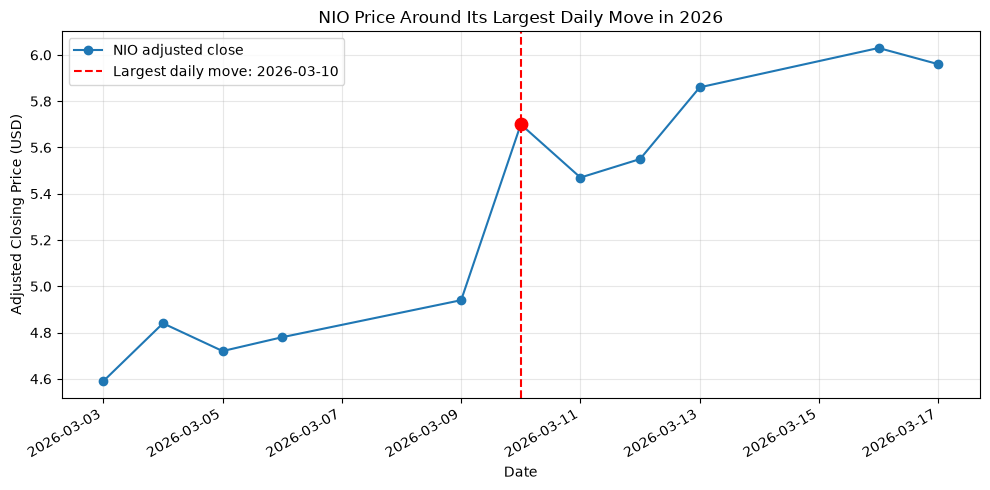

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    event_window.index,
    event_window["Close"],
    marker="o",
    label="NIO adjusted close"
)
ax.axvline(
    event_date,
    color="red",
    linestyle="--",
    label=f"Largest daily move: {event_date:%Y-%m-%d}"
)
ax.scatter(
    event_date,
    nio.loc[event_date, "Close"],
    color="red",
    s=80,
    zorder=5
)

ax.set_title("NIO Price Around Its Largest Daily Move in 2026")
ax.set_xlabel("Date")
ax.set_ylabel("Adjusted Closing Price (USD)")
ax.grid(alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Figure caption:** NIO's adjusted closing price around its largest absolute
daily return in the study period. The red dashed line marks March 10, 2026,
when the stock rose 15.38% from the previous trading day's close. The window
low is \$4.59 on March 3 and the window high is \$6.03 on March 16. The chart
shows that the jump was followed by several rising sessions rather than an
immediate reversal, which matters because it suggests the market was
re-pricing the company rather than reacting for a single day.

In [15]:
peer_tickers = ["TSLA", "BYDDY", "NIO"]

peers = yf.download(
    peer_tickers,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)

peer_prices = peers["Close"].reindex(columns=peer_tickers).sort_index()
peer_returns = peer_prices.pct_change(fill_method=None) * 100

event_day = pd.DataFrame({
    "Close (USD)": peer_prices.loc[event_date].round(2),
    "Daily Return (%)": peer_returns.loc[event_date].round(2)
})
event_day.index.name = "Ticker"

print("Daily returns on", event_date.date())
display(event_day)

Daily returns on 2026-03-10


,Close (USD),Daily Return (%)
Ticker,,
TSLA,399.24,0.14
BYDDY,12.22,-1.84
NIO,5.70,15.38


**Table caption:** Closing prices and daily returns for the three companies on
March 10, 2026, downloaded with the same date range used throughout this
project. NIO rose 15.38% while Tesla rose only 0.14% and BYD fell 1.84%.

This table is useful because it shows the move was mostly about NIO. If the
reason had been EV industry news or the overall market, the other two stocks
would probably have moved too. They barely moved, so the jump looks like it
came from something specific to NIO.

### Possible Business Explanation

NIO released its fourth-quarter 2025 financial results on **March 10, 2026**,
the same day as the price jump.

According to Nasdaq and Sina Finance reporting, the results showed that NIO
achieved the **first quarterly net profit in its history**, of RMB 283 million
(about US\$40.4 million). Adjusted operating profit was RMB 1.25 billion
(about US\$178.9 million), above the upper end of the US\$100-172 million
range the company had guided to a month earlier. Quarterly revenue was
RMB 34.65 billion, up 75.9% year over year and a company record, while vehicle
margin reached 18.1% and total gross margin 17.5%.

The company also gave strong guidance for the first quarter of 2026, expecting
deliveries of 80,000-83,000 vehicles (up 90.1%-97.2% year over year) and
revenue of RMB 24.48-25.18 billion. Cash reserves rose to RMB 45.9 billion,
and NIO reported a second consecutive quarter of positive free cash flow.

A first-ever profit changes how investors value a company that had been
loss-making for eleven years, which plausibly explains both the size of the
move and the unusually heavy trading volume.

### Connecting the Explanation Back to the Data

1. **The timing matches.** The earnings report and the price jump happened on
   the same day, March 10, 2026. The timing fits, but timing alone does not
   prove that the earnings caused the jump.

2. **Volume was much higher than usual.** Volume was 147,968,700 shares, about
   **4.06 times** the previous 20-day average. If many investors were reacting
   to the same news on the same day, we would expect to see trading this heavy.

3. **The other two stocks did not move.** Tesla rose only 0.14% and BYD fell
   1.84% on the same day. That makes it unlikely the jump came from EV industry
   news or the broader market, and points to NIO's own news instead.

These patterns fit the earnings explanation, but they do not prove it. Other
news on the same day and investor sentiment could also have played a part.

### Sources

1. Nasdaq (Howard Smith, Motley Fool). "Stock Market Today, March 10: Nio
   Surges After Posting First Quarterly Net Profit." March 10, 2026.
   https://www.nasdaq.com/articles/stock-market-today-march-10-nio-surges-after-posting-first-quarterly-net-profit

2. Nasdaq. "Why Did Nio Stock Jump 10% Today?" March 10, 2026.
   https://www.nasdaq.com/articles/why-did-nio-stock-jump-10-today

3. Sina Finance / Gelonghui. "美股异动丨蔚来盘前涨超6% Q4实现公司季度首次盈利 现金储备环比大增近百亿."
   March 10, 2026.
   https://finance.sina.com.cn/stock/bxjj/2026-03-10/doc-inhqpaek6240600.shtml


## Additional NIO Visualizations

The three charts below describe NIO's full-period performance and return
distribution. They complement the group-level charts in
`comparison_analysis.ipynb`, which compare all three companies together.

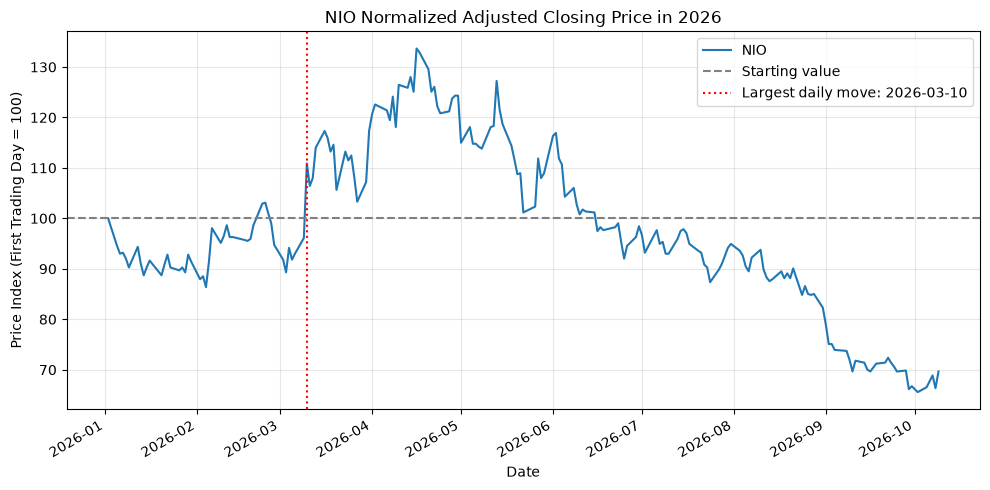

First trading day: 2026-01-02
Last trading day: 2026-10-09
Price change over the study period: -30.35%


In [17]:
normalized_price = nio["Close"] / nio["Close"].iloc[0] * 100
period_return = (
    nio["Close"].iloc[-1] / nio["Close"].iloc[0] - 1
) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(nio.index, normalized_price, label="NIO")
ax.axhline(100, color="gray", linestyle="--", label="Starting value")
ax.axvline(
    event_date,
    color="red",
    linestyle=":",
    label=f"Largest daily move: {event_date:%Y-%m-%d}"
)

ax.set_title("NIO Normalized Adjusted Closing Price in 2026")
ax.set_xlabel("Date")
ax.set_ylabel("Price Index (First Trading Day = 100)")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print("First trading day:", nio.index[0].date())
print("Last trading day:", nio.index[-1].date())
print(f"Price change over the study period: {period_return:.2f}%")

**Figure caption:** NIO's adjusted closing price over the full study period,
normalized to 100 on the first trading day, with the March 10 event marked by a
red dotted line. The chart puts the event in context: the March jump was large,
but NIO's price peaked later around April (monthly average \$6.40) and then
declined steadily to September (monthly average \$3.67). A single positive
earnings surprise did not change the direction of the full-period trend. This
is important for interpretation: explaining why the stock jumped on March 10
does not explain why it ended the period down.

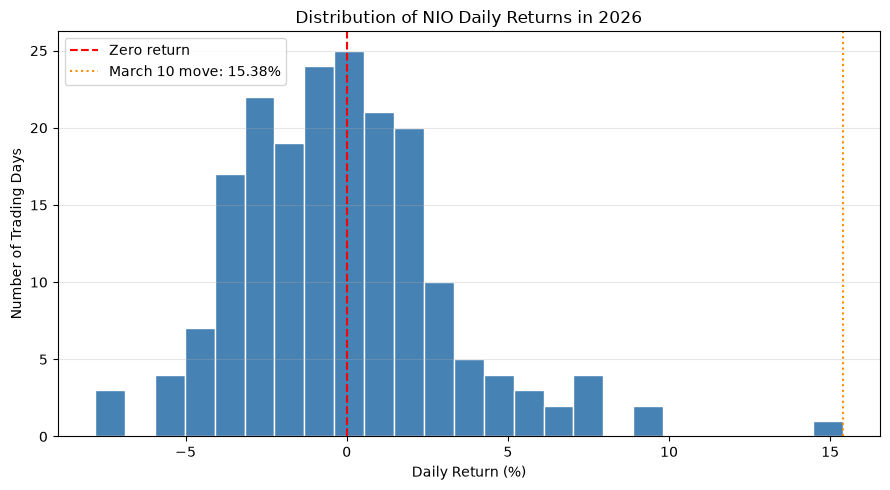

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    nio["Daily_Return_Pct"].dropna(),
    bins=25,
    color="steelblue",
    edgecolor="white"
)
ax.axvline(0, color="red", linestyle="--", label="Zero return")
ax.axvline(
    nio.loc[event_date, "Daily_Return_Pct"],
    color="darkorange",
    linestyle=":",
    label=f"March 10 move: {nio.loc[event_date, 'Daily_Return_Pct']:.2f}%"
)

ax.set_title("Distribution of NIO Daily Returns in 2026")
ax.set_xlabel("Daily Return (%)")
ax.set_ylabel("Number of Trading Days")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Figure caption:** Distribution of NIO's daily percentage returns during the
study period, with the March 10 move marked by the orange dotted line. Most
daily returns fall in a narrow band near zero, while the March 10 gain sits far
out in the right tail. This confirms that March 10 was genuinely unusual for
NIO rather than a typical day, which is why it is worth researching a business
explanation for it.

### Main Findings

1. **NIO ended the study period 30.35% below where it started.** The adjusted
   closing price fell from its January 2 level to the close on October 9, 2026.
   The March jump did not reverse the overall decline: the monthly average price
   peaked in April at \$6.40 and then fell to \$3.67 in September.

2. **NIO's largest absolute daily move was March 10, 2026, +15.38%**, with the
   adjusted close rising from \$4.94 to \$5.70.

3. **The move came with unusually heavy trading.** Volume reached 147,968,700
   shares, about 4.06 times the previous 20-trading-day average, which suggests
   many investors traded on the same information that day.

4. **The move was specific to NIO.** On the same day Tesla rose 0.14% and BYD
   fell 1.84%, so the explanation has to be something about NIO itself.

5. **The researched explanation is NIO's Q4 2025 earnings report**, released the
   same day, which showed the company's first-ever quarterly net profit and
   strong Q1 2026 guidance. The timing, the volume spike, and the lack of a
   similar move in the other two stocks all fit this explanation.

### Limitations

- Our data shows a possible explanation, not a proven cause. News timing, price
  moves, and volume can fit an explanation without proving it. Investor
  sentiment and other same-day news could also have mattered.
- There is a small difference between our data and the news reports on volume:
  `yfinance` shows 147,968,700 shares for March 10, while one article says
  145.1 million. The difference does not change the conclusion.
- March 10 is only one day out of 194, so conclusions from this single event
  say little about the rest of the period.
- This analysis is descriptive. It is historical observation, not a prediction
  and not investment advice.
- The comparison uses securities traded in different markets. BYDDY is a U.S.
  OTC-traded depositary receipt and NIO trades as depositary shares, so
  liquidity and trading hours differ, which can affect short-term comparisons.